In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('Lecture_2_University_Dataset.csv')


In [3]:
df.head()

,Student_ID,Program,Year_Level,GPA,Attendance_Percent,Registered_Credits,Satisfaction,Enrollment_Date,Campus
0,S001,Information Systems,4,3.15,79,21,High,2025-09-04,Central
1,S002,Cybersecurity,3,3.48,80,12,High,2025-09-07,South
2,S003,Computer Science,2,2.68,79,15,High,2025-09-10,North
3,S004,AI,1,3.24,85,18,High,2025-09-13,Central
4,S005,AI,4,3.23,78,21,Low,2025-09-16,South


In [4]:
df.dtypes

Student_ID             object
Program                object
Year_Level              int64
GPA                   float64
Attendance_Percent      int64
Registered_Credits      int64
Satisfaction           object
Enrollment_Date        object
Campus                 object
dtype: object

In [77]:
df['Enrollment_Date']=pd.to_datetime(df['Enrollment_Date'])

In [78]:
df.dtypes

Student_ID                    object
Program                       object
Year_Level                     int64
GPA                          float64
Attendance_Percent             int64
Registered_Credits             int64
Satisfaction                  object
Enrollment_Date       datetime64[ns]
Campus                        object
dtype: object

# Task 1

In [79]:
data_dictioary=pd.DataFrame({
    'column':['Student_ID','Program','Year_Level','GPA','Attendance_Percent','Registered_Credits','Satisfaction','Enrollment_Date','Campus'],
    ' storage dtype':['object','object','int64','float64','int64','int64','object','datetime64','object'],
    'semantic variable type':['categorical-(identifier)','categorical','Categorical-(ordinal)','Quantitative','Quantitative','Quantitative','categorical  (ordinal)','Temporal','categorical'],
    'Measurement scale':['nominal','nominal','ordinal','interval','ratio','ratio','ordinal','Temporal','nominal'],
    'Permissible operation':['Count unique IDs','Frequency count','Frequency count; preserve order','mean/median/standard deviation','mean/median/correlation','sum/mean','Frequency count; preserve order','Monthly aggregation; chronological ordering','Frequency count']
    })

In [80]:
data_dictioary

,column,storage dtype,semantic variable type,Measurement scale,Permissible operation
0,Student_ID,object,categorical-(identifier),nominal,Count unique IDs
1,Program,object,categorical,nominal,Frequency count
2,Year_Level,int64,Categorical-(ordinal),ordinal,Frequency count; preserve order
3,GPA,float64,Quantitative,interval,mean/median/standard deviation
4,Attendance_Percent,int64,Quantitative,ratio,mean/median/correlation
5,Registered_Credits,int64,Quantitative,ratio,sum/mean
6,Satisfaction,object,categorical (ordinal),ordinal,Frequency count; preserve order
7,Enrollment_Date,datetime64,Temporal,Temporal,Monthly aggregation; chronological ordering
8,Campus,object,categorical,nominal,Frequency count


### why Student_ID is not a quantitative measure :
##### Student_ID is used to uniquely identify students . tho it may contain numerical digit , these values doesnt represent measurable quantities .Therefore mathemtical operations such as calculating the mean or sum have no meningful interpretation

### Year_Level requires attention to ordering.
##### year level is a categorical variable but it has a natural ordering in it , so we should preserve this order during analysis and visualisation, so we dont lose meaningfull information

# Task 2

#### Task 2-a
#### Student count in each programt.

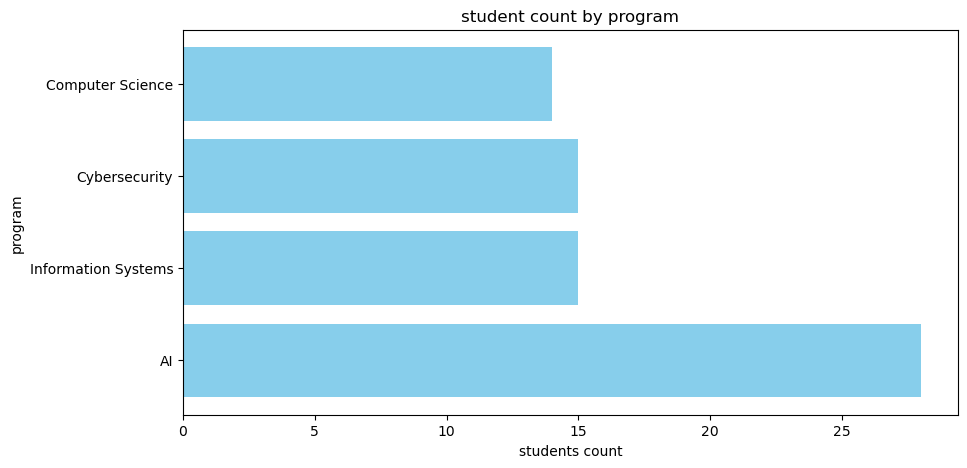

In [159]:
x=df['Program'].value_counts()
df_program_cat=x.index
stu_count=x.values

plt.figure(figsize=(10,5))
plt.xlabel('students count')
plt.ylabel('program')
plt.barh(x.index,x.values,color='skyblue')
plt.title('student count by program')
plt.savefig('Student count in each program.png',bbox_inches='tight')
plt.show()



### Taks 2-b GPA distribution
### How are students GPAs distributed, and where are GPA values most concentrated?t

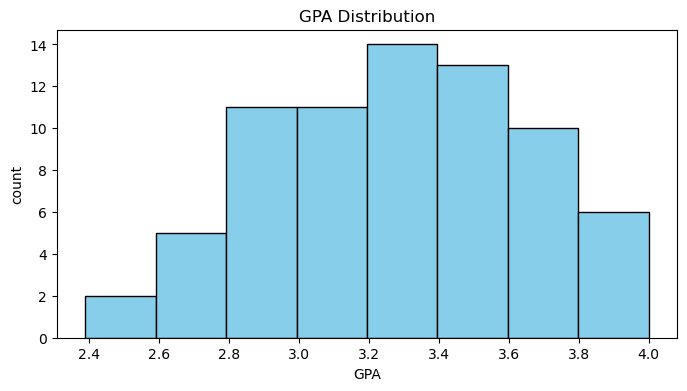

In [160]:
### Histogram
plt.figure(figsize=(8,4))
plt.title('GPA Distribution')
plt.hist(df['GPA'],bins=8,edgecolor='black',color='skyblue')
plt.xlabel('GPA')
plt.ylabel('count')
plt.savefig('SGPA distribution.png',bbox_inches='tight')
plt.show()


#### justify bin count
#### Eight bins were selected to provide a resonable level of details while keeping the distribution easy to interpret.Too few bins may hide pattern, while too many bins make the histogram difficult to interpret

## Task 2-c
### Is there a relationship between students' attendance percentages and their GPA?"

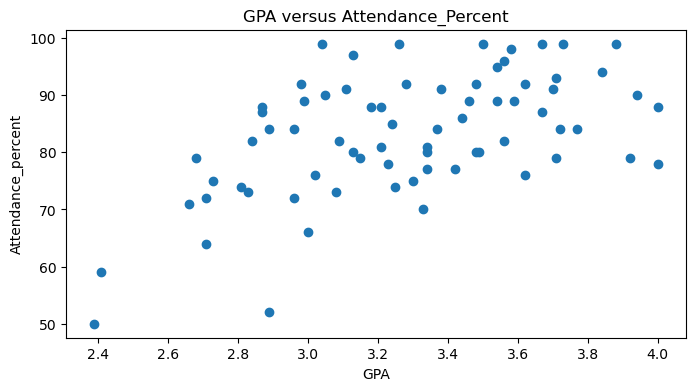

In [162]:
plt.figure(figsize=(8,4))
plt.xlabel('GPA')
plt.ylabel('Attendance_percent')
plt.scatter(df['GPA'],df['Attendance_Percent'])
plt.title('GPA versus Attendance_Percent')
plt.savefig('GPA versus Attendance_Percent.png',bbox_inches='tight')
plt.show()

### Task2_d 
### How are students satisfaction levels distributed across Low, Medium, and High categories?

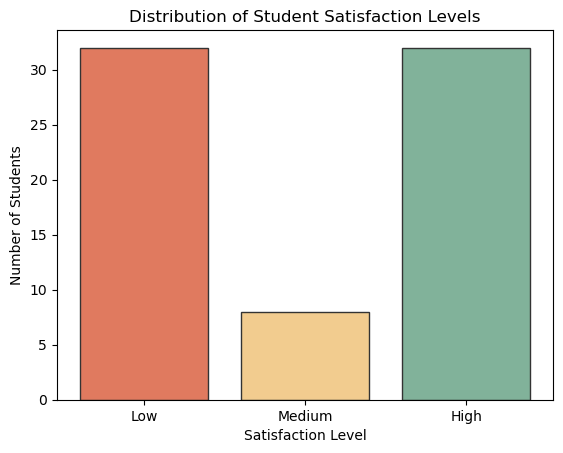

In [163]:
order = ['Low', 'Medium', 'High']

satisfaction_counts = df['Satisfaction'].value_counts().reindex(order)
colors = ['#E07A5F', '#F2CC8F', '#81B29A']

plt.bar(
    satisfaction_counts.index,
    satisfaction_counts.values,
    color=colors,
    edgecolor='#333333'
)

plt.title('Distribution of Student Satisfaction Levels')
plt.xlabel('Satisfaction Level')
plt.ylabel('Number of Students')
plt.savefig('Distribution of Student Satisfaction Levels.png',bbox_inches='tight')
plt.show()

### Task2-E
### How does the number of student enrollments vary across the months?

In [119]:
monthly_counts = df.groupby(
    df['Enrollment_Date'].dt.month).size()

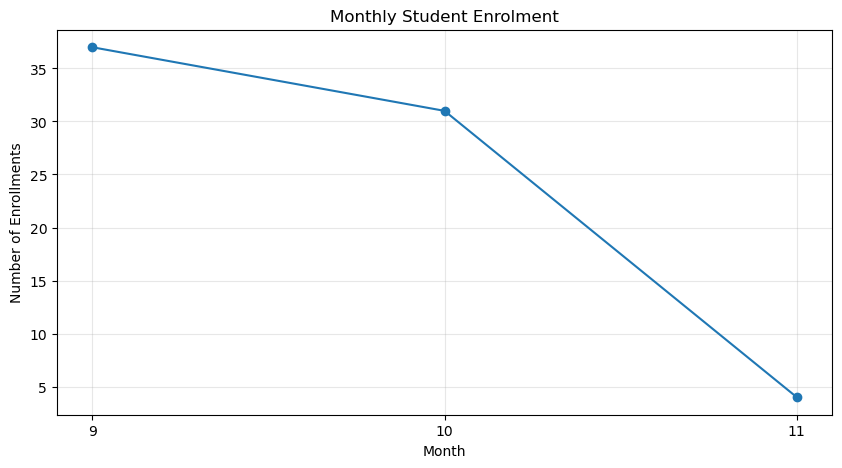

In [165]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_counts.index.astype(str),
    monthly_counts.values,
    marker='o'
)

plt.title('Monthly Student Enrolment')
plt.xlabel('Month')
plt.ylabel('Number of Enrollments')
plt.grid(alpha=0.3)
plt.savefig('Monthly Student Enrolment.png',bbox_inches='tight')
plt.show()

### Task 3 
a bar chart comparing Program A = 80 students and Program B = 100 students, with a vertical 
axis starting at 75(

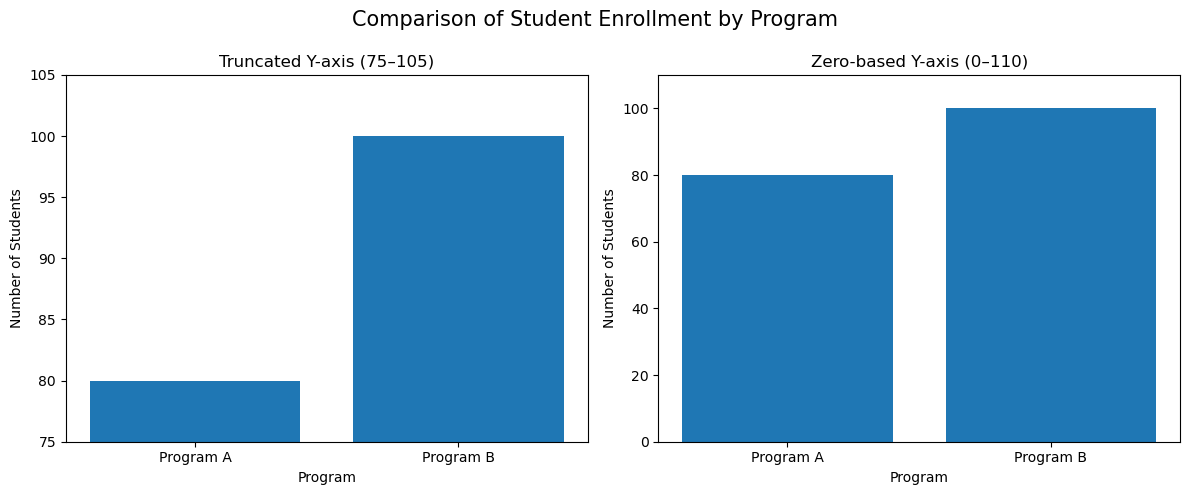

In [166]:
import matplotlib.pyplot as plt

programs = ['Program A', 'Program B']
students = [80, 100]

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left plot: misleading chart
axes[0].bar(programs, students)
axes[0].set_ylim(75, 105)
axes[0].set_title('Truncated Y-axis (75–105)')
axes[0].set_xlabel('Program')
axes[0].set_ylabel('Number of Students')

# Right plot: corrected chart
axes[1].bar(programs, students)
axes[1].set_ylim(0, 110)
axes[1].set_title('Zero-based Y-axis (0–110)')
axes[1].set_xlabel('Program')
axes[1].set_ylabel('Number of Students')

# One main title over both plots
fig.suptitle('Comparison of Student Enrollment by Program', fontsize=15)

# Adjust spacing so titles don't overlap
plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.savefig('Comparison of Student Enrollment by Program.png',bbox_inches='tight')
plt.show()

 #### (a) Explain why this can mislead viewers.
The side by side design compares two bar charts : one with a vertical axis starting at 75 and the other starting at zero.

the left chart is misleading because it exaggrates the differences between the two programs making the gap appear much larger than it actually is. 
This happens because the vertical axis starting at 75 instead of zero, cutting off the lower parts of the bars.

The redesigned chart on the right starts the vertical axis at zero , allowing viewres to provide the actual difference between the two values more accuratly.Since bar charts use the length of bars to represent quanities , starting at zero preserve the propotional relationship between the values and improve perceptual accuracy.

### (b) Redesign it appropriately (zero-based bars or another defensible encoding)

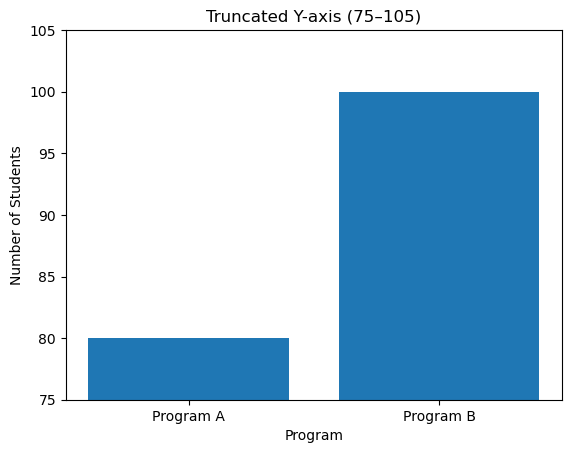

In [169]:
### the misleading chart indivisually 
plt.bar(programs, students)
plt.ylim(75, 105)
plt.title('Truncated Y-axis (75–105)')
plt.xlabel('Program')
plt.ylabel('Number of Students')
plt.savefig('Truncated Y-axis (75–105).png',bbox_inches='tight')


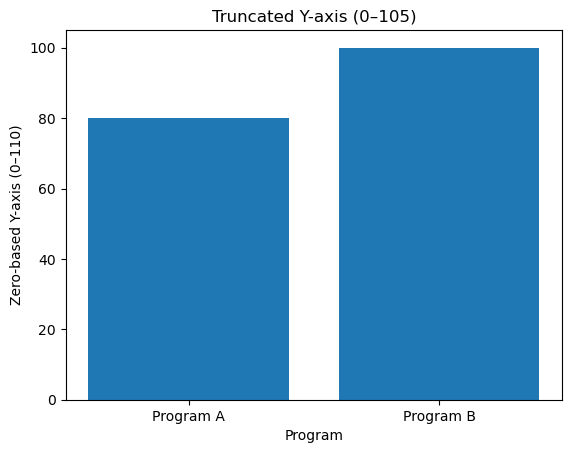

In [170]:
##the accurate chart
plt.bar(programs, students)
plt.ylim(0, 105)
plt.title('Truncated Y-axis (0–105)')
plt.xlabel('Program')
plt.ylabel('Zero-based Y-axis (0–110)')
plt.savefig('TZero-based Y-axis (0–110).png',bbox_inches='tight')


#### Task3-c Write 120–180 words defending the new chart, including visual channel and scale choices 

The redesigned chart uses a vertical bar chart with a zero-based y-axis to compare the number of students in Program A and Program B. The visual channel used is the length of the bars, while their position along a common quantitative scale allows viewers to compare the values accurately. Starting the y-axis at zero is important because bar charts represent quantities through bar length. If the axis starts at 75, the difference between 80 and 100 students appears much larger than it actually is, which can mislead viewers. By starting the scale at zero, the chart preserves the proportional relationship between the two values and provides a more accurate visual comparison. Additionally, clear axis labels and a descriptive title help viewers understand the information without confusion. Overall, this redesign improves perceptual accuracy and presents the data in an honest and understandable way.

### Task4

#### Which categorical chart was most useful and why?
the horizontal bar chart comparing stuents counts across programs was the most useful because it made it easy to compare categories and identify which programhad the highest and lowest number of students.Sorting the bars also made the differences easier to understand.


#### What did the histogram reveal that an average GPA alone could not?
histogram revealed how GPAs were disriputed among students, including where values were concentrated, how spread out they were, and whether there were unusually high or low values .An average GPA provides only one summery value and does not show the overall distribution

#### Does the scatterplot demonstrate causation? 
No.scatterplot can show whether there is an association between attendance percentage and GPA, but it cannot prove the higher attendance causes higher GPA.Other factors , such as study habits, otivations, and course difficulty , may also influece GPA.

#### Describe one case where a map would be inappropriate
A map would be inappropriate for comparing student satisfaction levels accross categories such as low,medium and high because they doesnt represent geographical locations. A bar chart would be more suitable for comparison.

#### Explain two accessibility improvements you made
1.Clear labels and titles: I used descriptive titles and axis labels to help viewers understand the information without confusion.

2.Meaningful colors and sorting: I used distinguishable colors to make categories easier to identify and sorted the bars to make comparisons easier.

3.Side-by-side comparison: I placed the misleading and redesigned charts next to each other so viewers can easily recognize how the axis scale changes the visual interpretation.e?

### Bonus

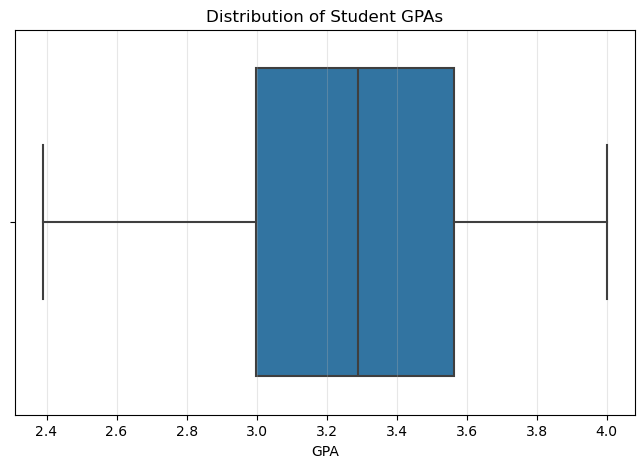

In [172]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='GPA')

plt.title('Distribution of Student GPAs')
plt.xlabel('GPA')
plt.grid(axis='x', alpha=0.3)
plt.savefig('box_plot_alternative')
plt.show()

### comparing reading accuracy and audience suitability:


The histogram and box plot both represent the distribution of student GPAs, but they highlight different aspects of the data. The histogram provides more detail about the frequency and concentration of GPA values, making it easier to identify the shape of the distribution and where most students' GPAs fall. In contrast, the box plot summarizes the distribution using the median, quartiles, and potential outliers, allowing for a quick comparison of spread and central tendency. The histogram is more suitable for general audiences who want to understand the overall distribution, while the box plot is useful for analytical audiences interested in statistical summaries.